# Bab 6 — Advanced Logistic Regression and Extensions

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

| No | Resep | Dataset | Inti |
|----|-------|---------|------|
| 1 | Ikhtisar regresi logistik | Breast Cancer | fungsi sigmoid, log-odds, MLE |
| 2 | Teknik klasifikasi multikelas | Iris | One-vs-Rest vs Multinomial (softmax) |
| 3 | Regularisasi | Breast Cancer | L2 vs L1, parameter `C`, jalur koefisien |
| 4 | Klasifikasi multilabel | sintetis (5 label) | satu model biner per label, ko-okurensi label |
| 5 | Metrik evaluasi | Breast Cancer | accuracy, precision, recall, F1, ROC–AUC |
| 6 | Latihan | Breast Cancer, Iris, sintetis 2D | L1, multinomial, visualisasi batas keputusan |

## Resep 1 — Ikhtisar Regresi Logistik

### Teori
Untuk target biner $y\in\{0,1\}$, regresi logistik memodelkan probabilitas kelas positif:
$$P(y=1\mid\mathbf{x}) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = \mathbf{w}^\top\mathbf{x}+b$$

Fungsi sigmoid $\sigma$ memetakan $z \in (-\infty,\infty)$ ke $(0,1)$. Dengan membalik rumusnya, kita mendapat **log-odds (logit)** yang linear terhadap fitur:
$$\log\frac{P(y=1\mid\mathbf x)}{1-P(y=1\mid\mathbf x)} = \mathbf{w}^\top\mathbf{x}+b$$
Artinya, kenaikan satu satuan fitur $x_j$ mengalikan **odds** dengan $e^{w_j}$ (*odds ratio*). **Batas keputusan** pada ambang 0,5 adalah $\mathbf{w}^\top\mathbf{x}+b=0$ — sebuah hyperplane (garis lurus di 2D).

**Pelatihan dengan Maximum Likelihood.** Parameter dipilih untuk memaksimalkan likelihood data, setara dengan meminimalkan **log-loss / binary cross-entropy**:
$$\mathcal{L}(\mathbf w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\Big]$$
Fungsi ini **konveks**, sehingga punya satu minimum global, tetapi tidak punya solusi bentuk tertutup. Solver numerik (`lbfgs`, `liblinear`, `newton-cg`, `saga`) mencarinya secara iteratif — itulah sebabnya kadang perlu menaikkan `max_iter` jika muncul *ConvergenceWarning*. Gradiennya sangat sederhana: $\nabla_{\mathbf w}\mathcal L = \frac1n\mathbf X^\top(\hat{\mathbf p}-\mathbf y)$.

Catatan: secara default scikit-learn **selalu** menambahkan regularisasi L2 dengan `C=1.0`.

### Persiapan — dataset Breast Cancer Wisconsin
569 sampel, 30 fitur; label 0 = *malignant* (ganas), 1 = *benign* (jinak).

In [ ]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Convert to DataFrame for easier manipulation (optional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

# Split the Data
X_train, X_test, y_train, y_test = train_test_split(df[data.feature_names],
                                                    df['target'],
                                                    test_size=0.2,
                                                    random_state=2024)

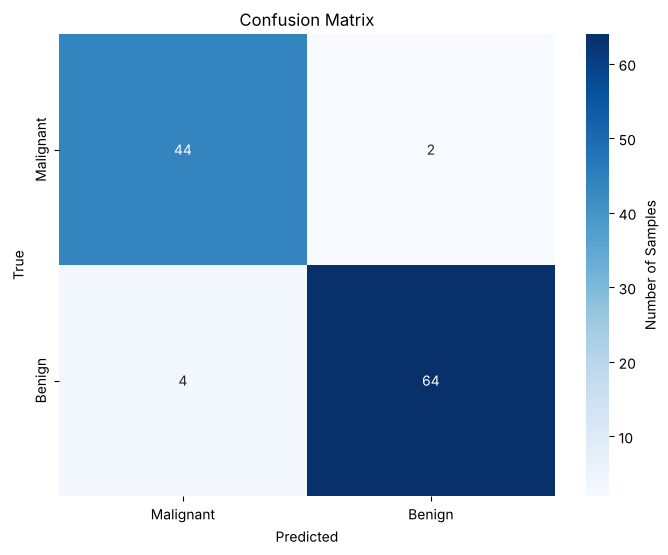

Accuracy: 0.95


Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [ ]:
# Create a Logistic Regression Model
model = LogisticRegression(max_iter=10000) # Increase max_iter if convergence issues occur

# Train the Model
model.fit(X_train, y_train)

# Make Predictions
y_pred = model.predict(X_test)

# Evaluate Performance
accuracy = accuracy_score(y_test, y_pred)

# Generate and plot confusion matrix
class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Get classification report as a dictionary
report_dict = classification_report(y_test, y_pred,
                                  target_names=class_names,
                                  output_dict=True)

# Create a DataFrame for better visualization
report_df = pd.DataFrame(report_dict).transpose()

# Style the DataFrame
styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f'Accuracy: {accuracy:.2f}\n')
print("\nClassification Report:")
display(styled_df)

**Interpretasi.** Akurasi ≈ 0,95 (108 dari 114 sampel uji benar). Confusion matrix: 44 dari 46 tumor ganas terdeteksi (2 lolos sebagai jinak), dan 4 tumor jinak salah dianggap ganas. Untuk kelas *Malignant*: precision ≈ 0,92 dan recall ≈ 0,96.

Model ini dilatih **tanpa scaling** sehingga solver butuh banyak iterasi (`max_iter=10000`) untuk konvergen — fitur dengan skala ribuan membuat permukaan loss memanjang dan sulit dioptimasi. Dalam konteks medis, 2 *false negative* (ganas yang lolos) adalah kesalahan paling mahal; ambang keputusan bisa digeser dari 0,5 untuk menurunkan jumlahnya, dengan konsekuensi lebih banyak *false positive*.

## Resep 2 — Teknik Klasifikasi Multikelas

### Teori
Ada dua cara memperluas regresi logistik ke $K > 2$ kelas.

**1. One-vs-Rest (OvR / One-vs-All).** Latih $K$ model biner terpisah; model ke-$k$ membedakan "kelas $k$" vs "semua kelas lain":
$$\hat p_k(\mathbf x) = \sigma(\mathbf w_k^\top\mathbf x + b_k), \qquad \hat y = \arg\max_k \hat p_k(\mathbf x)$$
Setiap model dilatih secara independen, sehingga probabilitasnya **tidak** otomatis berjumlah 1 (scikit-learn menormalkannya). Setiap sub-masalah juga tidak seimbang (1 kelas vs $K-1$ kelas).

**2. Multinomial (Softmax regression).** Satu model bersama dengan $K$ vektor bobot, dan probabilitas dihitung dengan **softmax**:
$$P(y=k\mid\mathbf{x}) = \frac{\exp(\mathbf{w}_k^\top\mathbf{x}+b_k)}{\sum_{j=1}^{K}\exp(\mathbf{w}_j^\top\mathbf{x}+b_j)}$$
Dilatih dengan meminimalkan **cross-entropy kategorikal** $-\frac1n\sum_i\sum_k \mathbb 1[y_i=k]\log \hat p_{ik}$. Probabilitas yang dihasilkan konsisten (berjumlah 1) dan biasanya lebih terkalibrasi bila kelas saling eksklusif. Ini adalah perilaku default `LogisticRegression` dengan solver `lbfgs`.

### Persiapan — dataset Iris (3 kelas)

In [ ]:
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### Membandingkan OvR dan Multinomial

Catatan versi: pada scikit-learn terbaru, solver `liblinear` tidak lagi menangani banyak kelas secara langsung. Agar kode buku tetap berjalan dengan perilaku OvR yang sama, model OvR dibungkus secara eksplisit dengan `OneVsRestClassifier` (inilah cara yang direkomendasikan dokumentasi scikit-learn). Di versi scikit-learn yang dipakai buku (1.5), `LogisticRegression(solver='liblinear')` sudah otomatis berstrategi OvR, jadi hasilnya setara.

In [ ]:
# Kode buku (resep "How to do it"), dengan OvR dibuat eksplisit melalui OneVsRestClassifier
from sklearn.multiclass import OneVsRestClassifier

# Create and train an OvR Logistic Regression model
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# Create and train and Multinomial Logistic Regression model
multinomial_model = LogisticRegression(solver='lbfgs', max_iter = 1000)
multinomial_model.fit(X_train, y_train)

# Make predictions with the OvR model
y_pred_ovr = ovr_model.predict(X_test)

# Make predictions with the Multinomial model
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the OvR model
accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
report_ovr = pd.DataFrame(classification_report(y_test, y_pred_ovr, output_dict=True)).transpose()
print("One-vs-Rest (OvR) Logistic Regression:")

styled_ovr = (report_ovr
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr)

# Evaluate the Multinomial model
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
report_multinomial = pd.DataFrame(classification_report(y_test, y_pred_multinomial, output_dict=True)).transpose()
print("Multinomial Logistic Regression:")

styled_multinomial = (report_multinomial
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_multinomial)

One-vs-Rest (OvR) Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


Multinomial Logistic Regression:


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


In [ ]:
# Ringkasan dan bukti perbedaan cara kerja keduanya
print('Akurasi OvR        : %.3f' % accuracy_ovr)
print('Akurasi Multinomial: %.3f' % accuracy_multinomial)
print('Jumlah model biner di OvR:', len(ovr_model.estimators_))

# Probabilitas multinomial = softmax dari skor linear
z = multinomial_model.decision_function(X_test[:3])
softmax = np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)
print('Softmax manual == predict_proba:', np.allclose(softmax, multinomial_model.predict_proba(X_test[:3])))

Akurasi OvR        : 0.956
Akurasi Multinomial: 0.933
Jumlah model biner di OvR: 3
Softmax manual == predict_proba: True


**Interpretasi.** Pada 45 sampel uji, OvR benar 43 (0,956) dan multinomial benar 42 (0,933) — selisihnya **satu sampel**. Keduanya mengklasifikasikan semua *Setosa* dengan benar, dan semua kesalahan terjadi antara *Versicolor* dan *Virginica*. Dengan data uji sekecil ini, selisih satu sampel tidak cukup untuk menyimpulkan bahwa OvR lebih baik; perbandingan yang adil memerlukan cross-validation.

Sel di atas juga membuktikan bahwa `predict_proba` pada model multinomial persis sama dengan **softmax** dari skor linear `decision_function`, dan bahwa OvR benar-benar terdiri dari 3 model biner.

### Pairplot fitur Iris
Pairplot membantu memahami **mengapa** sebagian kelas mudah dan sebagian sulit dipisahkan.

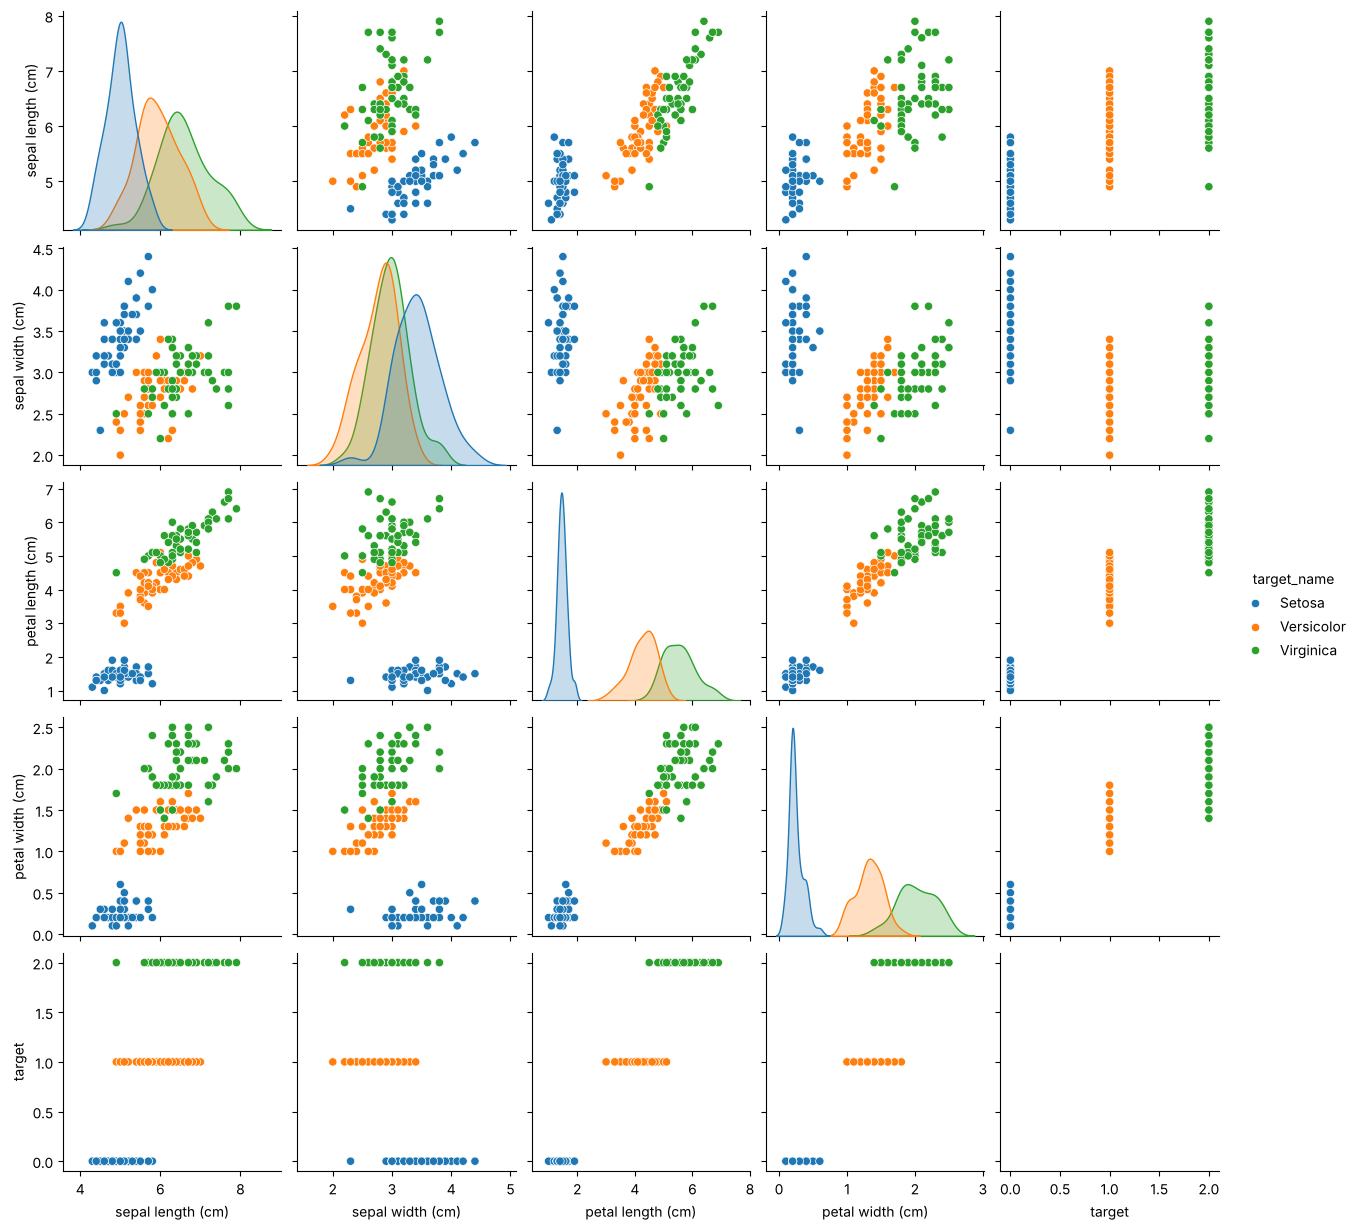

In [ ]:
# Create a pairplot to visualize the data
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df, hue='target_name', diag_kind='kde')
plt.show()

**Interpretasi.** Pada panel *petal length* dan *petal width*, *Setosa* terpisah sangat jauh dari dua kelas lain — sebuah garis lurus sudah cukup memisahkannya. *Versicolor* dan *Virginica* bersebelahan dan sedikit tumpang tindih, sehingga hampir semua kesalahan klasifikasi pada Iris terjadi di antara keduanya. Fitur *sepal* (kelopak luar) jauh kurang informatif karena distribusi ketiga kelas saling bertumpuk.

## Resep 3 — Regularisasi pada Regresi Logistik

### Teori
Fungsi objektif yang diminimalkan scikit-learn:
$$\min_{\mathbf w,b}\; \underbrace{C\sum_{i=1}^{n}\ell\big(y_i,\;\mathbf w^\top\mathbf x_i+b\big)}_{\text{kecocokan data}} \;+\; \underbrace{R(\mathbf w)}_{\text{penalti}}$$
dengan $R(\mathbf w) = \tfrac12\lVert\mathbf w\rVert_2^2$ (L2) atau $\lVert\mathbf w\rVert_1$ (L1).

Perhatikan bahwa **$C$ adalah kebalikan kekuatan regularisasi** ($C \approx 1/\alpha$): $C$ kecil → penalti dominan → regularisasi kuat → koefisien kecil; $C$ besar → model bebas menyesuaikan diri dengan data → risiko overfitting.

- **L2 (Ridge):** semua koefisien mengecil secara halus, jarang tepat nol, stabil terhadap fitur berkorelasi.
- **L1 (Lasso):** menghasilkan koefisien yang tepat nol → **model sparse** dan seleksi fitur otomatis. Hanya didukung oleh solver tertentu (`liblinear`, `saga`).

Regularisasi juga penting untuk alasan lain: jika data **terpisah sempurna** secara linear, MLE tanpa regularisasi tidak punya solusi berhingga (bobot terus membesar menuju tak hingga); penalti mencegah hal ini.

Fitur **wajib distandardisasi** agar penalti berlaku adil untuk semua koefisien.

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset and scale it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Create and train a Ridge (L2) regularized Logistic Regression model
ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

# Create and train a Lasso (L1) regularized Logistic Regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions with the Ridge model
y_pred_ridge = ridge_model.predict(X_test)

# Make predictions with the Lasso model
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Ridge model
accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
report_ridge = pd.DataFrame(classification_report(y_test, y_pred_ridge, output_dict=True)).transpose()
print("Ridge (L2) Regularized Logistic Regression:")

styled_ridge = (report_ridge
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ridge)

# Evaluate the Lasso model
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
report_lasso = pd.DataFrame(classification_report(y_test, y_pred_lasso, output_dict=True)).transpose()
print("Lasso (L1) Regularized Logistic Regression:")

styled_lasso = (report_lasso
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_lasso)

Ridge (L2) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) Regularized Logistic Regression:


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


In [ ]:
# Bandingkan jumlah fitur yang dipakai (koefisien tidak nol) oleh L2 vs L1 pada C = 0.1
print('Akurasi L2: %.3f | koefisien tidak nol: %d dari %d' % (accuracy_ridge, np.sum(ridge_model.coef_ != 0), X.shape[1]))
print('Akurasi L1: %.3f | koefisien tidak nol: %d dari %d' % (accuracy_lasso, np.sum(lasso_model.coef_ != 0), X.shape[1]))
print('\nFitur yang dipertahankan L1:')
print(list(np.array(feature_names)[lasso_model.coef_[0] != 0]))

Akurasi L2: 0.982 | koefisien tidak nol: 30 dari 30
Akurasi L1: 0.965 | koefisien tidak nol: 7 dari 30

Fitur yang dipertahankan L1:
[np.str_('mean concave points'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst smoothness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry')]


**Interpretasi.** Dengan regularisasi yang cukup kuat ($C = 0{,}1$) dan data terstandardisasi:
- **L2** mencapai akurasi ≈ 0,982 dan memakai **semua 30** fitur (koefisien kecil tetapi tidak nol).
- **L1** mencapai akurasi ≈ 0,965 dengan hanya **7 dari 30** fitur — model jauh lebih sederhana dengan penurunan akurasi kecil. Fitur yang dipertahankan sebagian besar adalah fitur "worst" (nilai terburuk dari inti sel) dan "concave points" (cekungan kontur inti sel), yang secara medis memang terkait dengan keganasan.

Bandingkan juga dengan Resep 1: tanpa scaling dan dengan $C=1$, akurasi hanya ≈ 0,95. Standardisasi + regularisasi yang sesuai menaikkan performa sekaligus mempercepat konvergensi.

### Jalur koefisien terhadap $C$

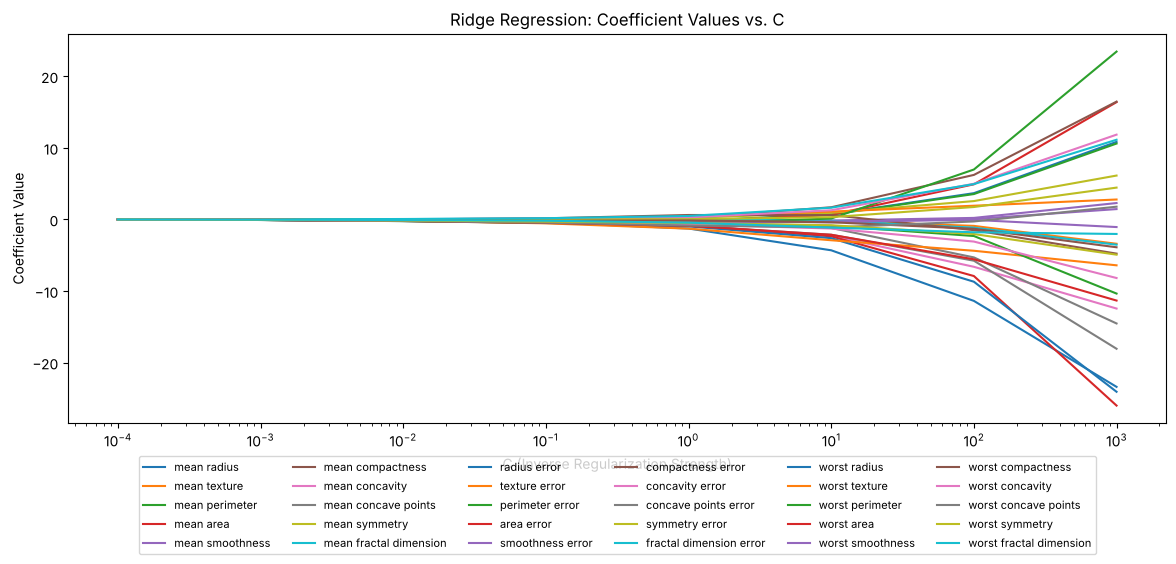

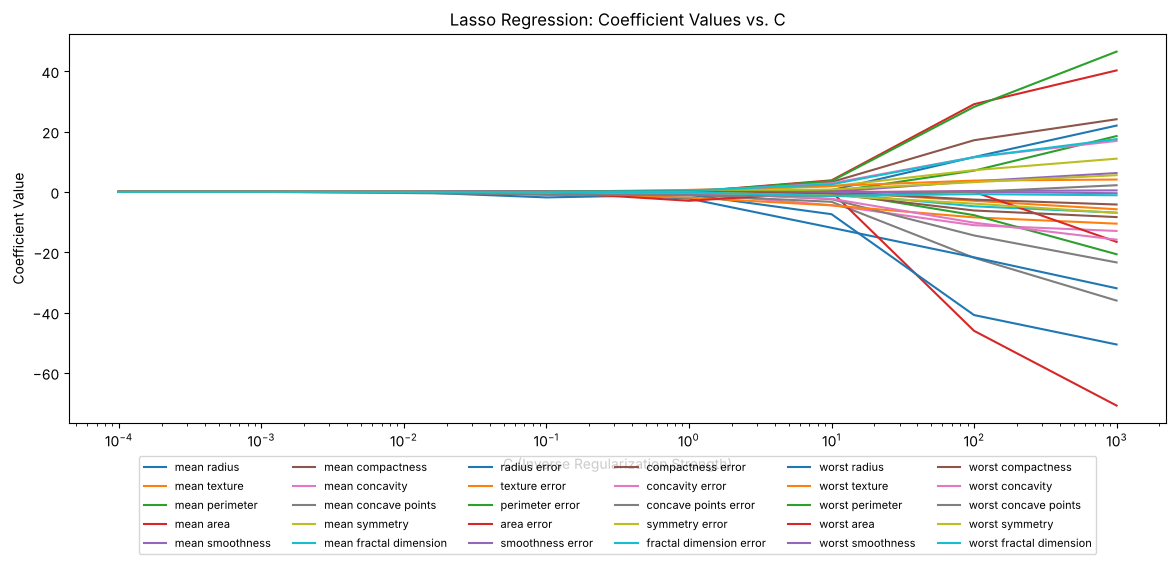

In [ ]:
# Plotting coefficients for different C values (Ridge)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []

for C in C_values:
    ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=C)
    ridge_model.fit(X_train, y_train)
    coefs_ridge.append(ridge_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_ridge], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

# Plotting coefficients for different C values (Lasso)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_lasso = []

for C in C_values:
    lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=C)
    lasso_model.fit(X_train, y_train)
    coefs_lasso.append(lasso_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_lasso], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi.** Di sisi kiri (C sangat kecil, regularisasi sangat kuat) semua koefisien berada di sekitar nol. Saat $C$ membesar:
- **L2**: semua koefisien tumbuh **bersamaan dan halus**, tidak ada yang tepat nol.
- **L1**: koefisien "menyala" **satu per satu** — fitur yang paling penting keluar dari nol lebih dulu, sementara fitur lain tetap tepat nol hingga $C$ cukup besar. Inilah perilaku seleksi fitur L1.

Di sisi kanan ($C$ sangat besar, regularisasi hampir hilang), beberapa koefisien membesar sangat jauh. Ini tanda model mulai bergantung pada kombinasi fitur yang saling berkorelasi (pada Breast Cancer, fitur *radius*, *perimeter*, dan *area* sangat berkorelasi), yaitu tanda overfitting.

## Resep 4 — Konsep Klasifikasi Multilabel

### Teori
- **Multikelas:** setiap sampel memiliki **tepat satu** dari $K$ kelas (misal jenis bunga).
- **Multilabel:** setiap sampel dapat memiliki **nol, satu, atau beberapa** label sekaligus (misal satu artikel bertopik "politik" *dan* "ekonomi"). Target berbentuk matriks biner $\mathbf Y\in\{0,1\}^{n\times L}$.

Pendekatan paling sederhana adalah **Binary Relevance**: latih satu classifier biner untuk setiap label secara independen (inilah yang dilakukan kode buku, setara dengan `MultiOutputClassifier`). Kelemahannya: korelasi antar-label diabaikan. Alternatif yang memodelkan korelasi adalah **Classifier Chains** (`ClassifierChain`), di mana prediksi label sebelumnya menjadi fitur untuk label berikutnya.

Metrik multilabel perlu hati-hati:
- `accuracy_score` pada multilabel = **subset accuracy** (*exact match ratio*): sampel dianggap benar hanya jika **semua** labelnya tepat. Sangat ketat.
- **Hamming loss** $= \frac{1}{nL}\sum_i\sum_l \mathbb 1[\hat y_{il}\ne y_{il}]$: proporsi label individual yang salah — lebih "pemaaf".
- Precision/recall/F1 per label, beserta rata-rata *micro* (dihitung dari total TP/FP/FN semua label), *macro* (rata-rata biasa antar label), dan *samples* (rata-rata per sampel).

In [ ]:
# Load the libraries
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
X, y = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)
df = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
df['target'] = list(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Since we have multiple labels, we need to train a separate model for each label
models = []
y_pred_all = []

# Train a model for each label (column) in y
for i in range(y_train.shape[1]):
    # Create and train model for this label
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)

    # Make predictions for this label
    y_pred_label = model.predict(X_test)
    y_pred_all.append(y_pred_label)

# Convert predictions list to array and transpose to match original format
y_pred = np.array(y_pred_all).T

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()
print("Classification Report:")

styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


In [ ]:
from sklearn.metrics import hamming_loss
print('Subset accuracy (semua label harus benar): %.3f' % accuracy)
print('Hamming loss (proporsi label yang salah) : %.3f' % hamming_loss(y_test, y_pred))
print('Rata-rata jumlah label per sampel        : %.2f' % y_test.sum(axis=1).mean())

Subset accuracy (semua label harus benar): 0.340
Hamming loss (proporsi label yang salah) : 0.209
Rata-rata jumlah label per sampel        : 1.87


**Interpretasi.** Subset accuracy hanya ≈ 0,34: hanya sepertiga sampel uji yang kelima labelnya tertebak **semua** dengan benar. Namun Hamming loss ≈ 0,21 berarti sekitar 79% keputusan label individual sudah benar. Perbedaan besar ini wajar — dengan 5 label, peluang semuanya benar sekaligus jauh lebih kecil daripada peluang tiap label benar. Selalu laporkan beberapa metrik untuk masalah multilabel.

Laporan klasifikasi per label memperlihatkan ketimpangan yang besar: label 0 dan 1 (muncul pada >55% sampel) memiliki recall ≈ 0,81–0,85, sedangkan label 3 — label paling jarang, hanya ≈11% sampel — memiliki recall ≈ 0,18, dan label 2 ≈ 0,33. Model biner untuk label yang jarang sangat tidak seimbang sehingga cenderung memprediksi "tidak ada label". Opsi perbaikannya antara lain `class_weight='balanced'` atau menurunkan ambang keputusan untuk label tersebut.

### Analisis ko-okurensi label
Matriks ko-okurensi $\mathbf{Y}^\top\mathbf{Y}$: elemen $(i, j)$ = jumlah sampel yang memiliki label $i$ **dan** label $j$; diagonal = frekuensi tiap label. Versi ternormalisasi (baris dibagi diagonal) memberi estimasi $P(\text{label } j \mid \text{label } i)$.


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


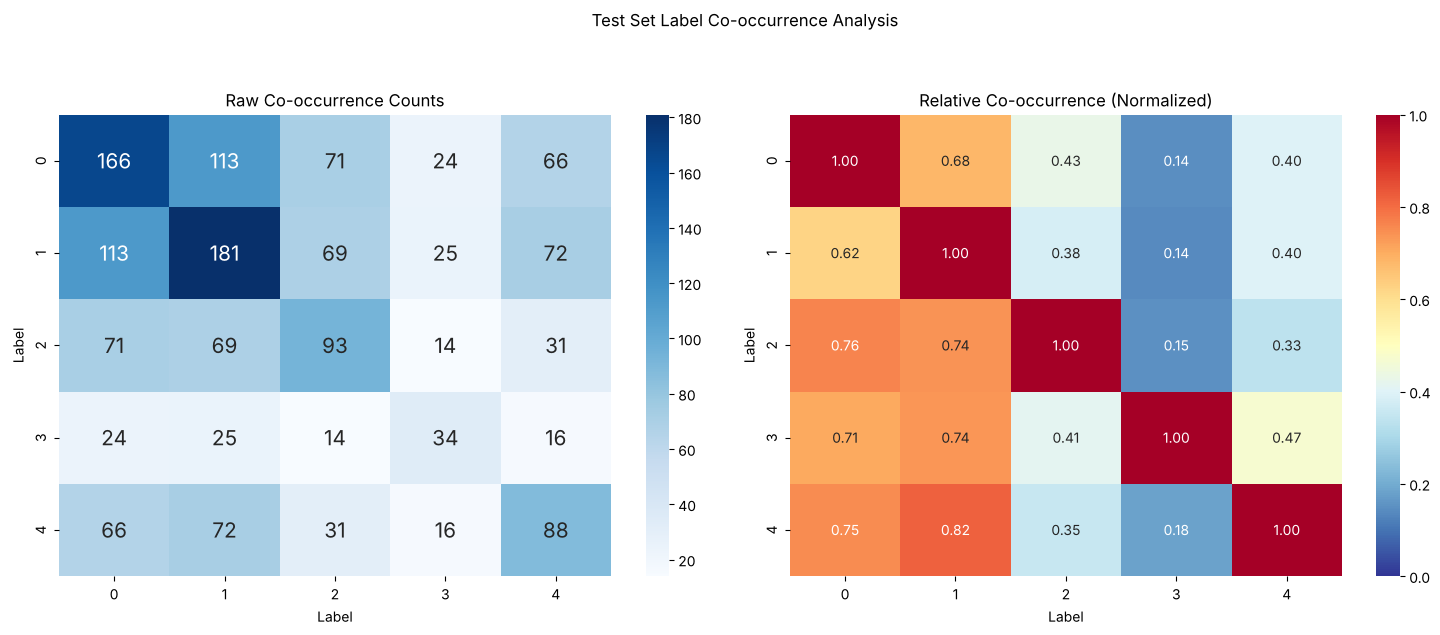

In [ ]:
# Create a detailed label co-occurrence visualization
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # Compute raw co-occurrence counts
    cooccurrence = y.T @ y

    # Compute relative co-occurrence (normalized by diagonal)
    # This shows what percentage of time label i occurs with label j
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Plot raw co-occurrence
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues',
                ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    # Plot relative co-occurrence
    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f',
                cmap='RdYlBu_r', ax=ax2, annot_kws={"fontsize": 10},
                vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')

    plt.suptitle(title, y=1.05)
    plt.tight_layout()

    # Print additional statistics
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        percentage = count / len(y) * 100
        print(f"Label {i}: {count} samples ({percentage:.1f}%)")

    print("\nMost common label combinations:")
    # Get unique combinations and their counts
    unique_combinations = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-unique_combinations[1])  # Sort by count (descending)
    for combo, count in zip(unique_combinations[0][sorted_idx][:5],
                          unique_combinations[1][sorted_idx][:5]):
        percentage = count / len(y) * 100
        print(f"Combination {combo}: {count} samples ({percentage:.1f}%)")

# Use the function on your test data
plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Interpretasi.** Matriks ko-okurensi menunjukkan bahwa beberapa label lebih sering muncul bersama dibanding yang lain, dan ada sampel tanpa label sama sekali (kombinasi `[0 0 0 0 0]`). Pola ketergantungan seperti ini **tidak dimanfaatkan** oleh pendekatan Binary Relevance di atas, karena setiap label dilatih sendiri-sendiri. Jika ko-okurensi kuat, `ClassifierChain` berpotensi meningkatkan subset accuracy.

## Resep 5 — Metrik Evaluasi Model

### Teori
Dari confusion matrix biner (TP, FP, TN, FN):

| Metrik | Rumus | Pertanyaan yang dijawab |
|---|---|---|
| Accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ | berapa proporsi prediksi yang benar? (menyesatkan bila kelas tidak seimbang) |
| Precision | $\frac{TP}{TP+FP}$ | dari yang diprediksi positif, berapa yang benar positif? |
| Recall / Sensitivity / TPR | $\frac{TP}{TP+FN}$ | dari semua positif sebenarnya, berapa yang tertangkap? |
| F1 | $\frac{2PR}{P+R}$ | keseimbangan precision dan recall |
| FPR | $\frac{FP}{FP+TN}$ | dari semua negatif, berapa yang salah dianggap positif? |

**ROC curve** memplot TPR terhadap FPR untuk **semua ambang** keputusan $t$ (prediksi positif jika $\hat p \ge t$). Menurunkan $t$ menaikkan recall tetapi juga FPR. **AUC** (luas di bawah kurva ROC) memiliki interpretasi probabilistik yang elegan:
$$\text{AUC} = P\big(\hat p(\mathbf x^+) > \hat p(\mathbf x^-)\big)$$
yaitu peluang model memberi skor lebih tinggi pada sampel positif acak dibanding sampel negatif acak. AUC = 0,5 setara tebakan acak (garis diagonal), AUC = 1 berarti pemisahan sempurna. AUC tidak bergantung pada ambang yang dipilih.

Catatan: pada dataset ini kelas positif (label 1) adalah **jinak**. Dalam konteks diagnosis, kesalahan terpenting adalah tumor ganas yang lolos, yang di sini terlihat sebagai *recall kelas 0* yang rendah.

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report:


,precision,recall,f1-score,support
0,0.924,0.910,0.917,67
1,0.943,0.952,0.947,104
accuracy,0.936,0.936,0.936,1
macro avg,0.934,0.931,0.932,171
weighted avg,0.936,0.936,0.936,171


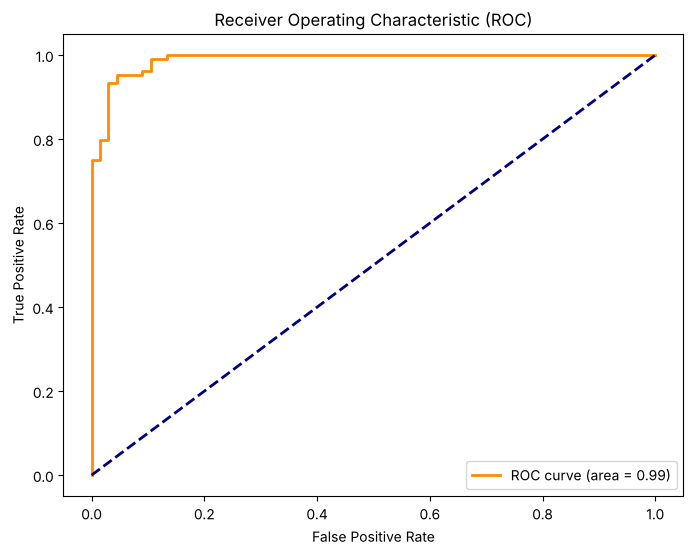

In [ ]:
# Load the model
model = LogisticRegression(solver='liblinear')

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
report = pd.DataFrame(classification_report(y_test, y_pred, zero_division=1, output_dict=True)).transpose()

# Print the metrics
print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report:")

styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi.** Model `liblinear` tanpa scaling memperoleh accuracy 0,94, precision 0,94, recall 0,95, F1 0,95, dan **ROC AUC 0,99**. Fungsi `precision_score`, `recall_score`, dan `f1_score` secara default menghitung untuk **kelas 1 (jinak)**. Untuk kelas ganas (kelas 0), recall ≈ 0,91, yaitu 6 dari 67 tumor ganas lolos.

AUC 0,99 yang hampir sempurna sementara akurasi "hanya" 0,94 menunjukkan bahwa model sebenarnya **memeringkat** sampel dengan sangat baik (hampir selalu memberi probabilitas lebih tinggi ke tumor jinak daripada ganas). Kesalahannya berasal dari **ambang 0,5** yang tidak optimal untuk data ini. Kurva ROC yang mepet ke pojok kiri atas memperlihatkan bahwa ada ambang yang memberi TPR tinggi dengan FPR sangat rendah.

## Latihan Praktik

### Latihan 1 — Regresi logistik dengan regularisasi L1 (Breast Cancer)

In [ ]:
#Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Lasso regularized Logistic Regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000, C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions with the Lasso model
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Lasso model performance
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso Model Accuracy: {accuracy_lasso:.2f}")

Lasso Model Accuracy: 0.95


In [ ]:
print('Jumlah fitur yang dipakai model L1: %d dari %d' % (np.sum(lasso_model.coef_ != 0), X.shape[1]))

Jumlah fitur yang dipakai model L1: 7 dari 30


**Interpretasi.** Regresi logistik L1 dengan $C=0{,}1$ pada data **tanpa scaling** mencapai akurasi 0,95 dan memakai 7 dari 30 fitur. Tanpa scaling, fitur berskala besar (misal *area*) lebih "murah" diberi koefisien kecil, sehingga pilihan fitur oleh L1 bisa berbeda dari versi terstandardisasi di Resep 3 meskipun jumlahnya kebetulan sama. Ini alasan lain mengapa scaling dianjurkan sebelum regularisasi.

### Latihan 2 — Regresi logistik multinomial (Iris)

In [ ]:
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Multinomial Logistic Regression model
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

# Make predictions with the Multinomial model
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the Multinomial model performance
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Model Accuracy: {accuracy_multinomial:.2f}")

Multinomial Model Accuracy: 0.93


**Interpretasi.** Akurasi multinomial 0,93 (42 dari 45), sama persis dengan Resep 2 karena data, pembagian, dan modelnya identik — ini juga menunjukkan bahwa hasilnya *reproducible* berkat `random_state=2024`.

### Latihan 3 — Visualisasi batas keputusan

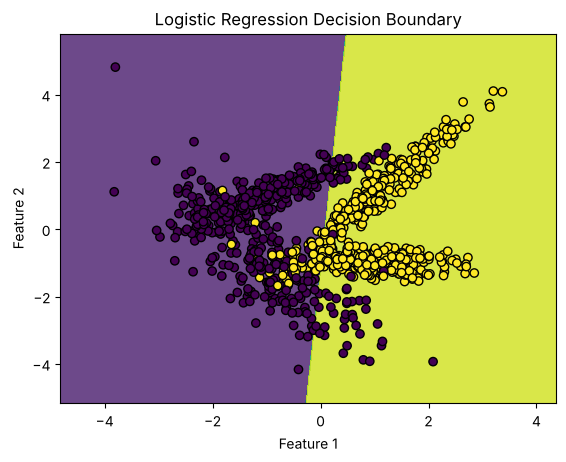

In [ ]:
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Create synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Logistic Regression model
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class probabilities across the grid
Z = logistic_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
# Persamaan batas keputusan: w1*x1 + w2*x2 + b = 0  ->  x2 = -(w1*x1 + b) / w2
w1, w2 = logistic_model.coef_[0]
b = logistic_model.intercept_[0]
print(f'Batas keputusan: x2 = {-w1/w2:.3f} * x1 + {-b/w2:.3f}')
print('Akurasi data uji: %.3f' % logistic_model.score(X_test, y_test))

Batas keputusan: x2 = 14.811 * x1 + -1.189
Akurasi data uji: 0.897


**Interpretasi.** Batas antara dua warna latar adalah **garis lurus**, sesuai teori: batas keputusan regresi logistik adalah himpunan titik dengan $\mathbf w^\top\mathbf x + b = 0$, dan persamaan garisnya dicetak di atas. Titik-titik yang berada di "wilayah warna yang salah" adalah sampel yang tidak bisa dipisahkan oleh garis lurus mana pun. Jika pola kelas sebenarnya melengkung, regresi logistik perlu dibantu fitur non-linear (misalnya `PolynomialFeatures`) atau diganti model non-linear (SVM kernel, pohon keputusan — Bab 7 dan 8).

## Kesimpulan Bab 6

- Regresi logistik memodelkan **log-odds** sebagai fungsi linear dari fitur dan dilatih dengan meminimalkan **log-loss** (MLE). Batas keputusannya linear.
- **Multikelas:** OvR melatih $K$ model biner independen; multinomial (softmax) melatih satu model bersama dengan probabilitas yang konsisten.
- **Regularisasi:** `C` adalah **kebalikan** kekuatan penalti. L2 mengecilkan koefisien, L1 menolkan koefisien (seleksi fitur). Standardisasi fitur terlebih dulu.
- **Multilabel:** satu classifier per label (Binary Relevance); evaluasi dengan subset accuracy dan Hamming loss, dan perhatikan ko-okurensi label.
- **Evaluasi:** jangan hanya melihat akurasi — gunakan precision, recall, F1, dan ROC–AUC sesuai biaya kesalahan pada masalahnya.